# 2 · Run ATHENA (README steps 3 and 4)

Kernel: the `athena` conda env. Run `1_prepare_data.ipynb` first.

This does what the ATHENA GUI's **GO** button does, without the GUI (`run_athena.py`):

| Phase | GUI section | What happens | Output (in the capture's project folder) |
|---|---|---|---|
| 1 | 2D Extraction | MediaPipe finds body (33 points) and hands (21 points each) in every frame of every camera, after undistorting the frame; then left/right hands are checked across cameras | `landmarks/<rec>/cam*/2Dlandmarks_*.npy` |
| 2 | Triangulation and Refinement | hand swaps corrected, points triangulated to 3D (outlier cameras dropped), smoothed, reprojected to every camera | `landmarks/<rec>/<rec>_3Dlandmarks.npy` (mm), `_2Dlandmarksrefined.npy`, videos in `videos_processed/<rec>/` |
| montage | `athena-montage` | all cameras' reprojected videos + the 3D view in one video | `videos_processed/<rec>/compilation.mp4` |

Timing for the 103 s test capture on this Mac: phase 1 ≈ 5 min; phase 2 ≈ 75 min, almost all of it drawing the reprojected 2D images (≈ 2 min with `save_images_refine=False`, but then no montage); montage ≈ 10 min.

In [1]:
from pathlib import Path
import json
import warnings
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
import prepare_athena as pa
import run_athena as ra

CAPTURE = None  # capture folder name; None = the most recent one in athena_projects/

PROJECT = pa.OUT_ROOT / CAPTURE if CAPTURE else sorted(p for p in pa.OUT_ROOT.iterdir() if p.is_dir())[-1]
RECORDINGS = ra.list_recordings(PROJECT)
problems = pa.check_project(PROJECT)  # README step 2, again, before spending time
assert not problems, problems
print(f"{PROJECT.name}: recordings {RECORDINGS}, calibration OK")

2026-10-20_103853_capture: recordings ['2026-10-20_103853_capture'], calibration OK


## Options (same names as the GUI)

Changed from the GUI defaults, measured on this kitchen:
- **pose/hand confidence 0.5 instead of 0.9**: at 0.9 the body is found in 0–3 of 7 test frames per camera and hands almost never; at 0.5 the body is found in most frames and both wrists triangulate in ~93% of frames. Going down to 0.3 adds only a few % more hands.
- **3D and reprojected videos on**: needed for the montage (step 4). The reprojected 2D images are what makes phase 2 slow (one image per frame per camera); turn `save_images_refine`/`save_video_refine` off when you only need the numbers.

**About hands.** The cameras see the whole room, so a hand is only ~40 px wide in a 1920 px frame, and MediaPipe's hand detector (which looks at the whole frame shrunk to 192 px) finds hands in only ~0–15% of frames per camera. Wrists and arms come from the body model and are fine. For fingers, the `"hamer"` backend looks for hands in crops around the body's wrists (much better at this scale) but is far slower and needs the MANO hand model, which you must download yourself after registering at https://mano.is.tue.mpg.de (`ra.hamer_missing()` tells you where to put it).

In [2]:
OPTIONS = dict(
    # 2D extraction
    fraction_frames=1.0,        # 1.0 = whole recording; e.g. 0.1 = first 10% for a quick test
    num_processes=9,            # cameras processed in parallel
    pose_confidence=0.5,        # GUI default 0.9 misses most bodies here
    hand_confidence=0.5,
    hand_backend="mediapipe",   # or "hamer" (see above)
    use_face_mesh=False,        # needs face_landmarker.task, not shipped with this install
    save_images_mp=False,       # 2D overlay images/videos: one PNG per frame per camera
    save_video_mp=False,
    # Triangulation and refinement
    refine_calibration=False,   # bundle-adjusts cameras on hand points; hands are too sparse here
    all_landmarks_lfc=10,       # smoothing cutoff, Hz
    save_images_triangulation=True, save_video_triangulation=True,  # 3D skeleton video
    save_images_refine=True, save_video_refine=True,                # reprojected 2D videos
)
RUN_2D, RUN_3D, RUN_MONTAGE = True, True, True  # set False to skip a step that is already done

## Step 3a · Phase 1: 2D landmarks in every camera

In [3]:
if RUN_2D:
    ra.detect_2d(PROJECT, RECORDINGS, **OPTIONS)

for rec in RECORDINGS:
    print(f"{rec}: share of frames with a detection, per camera")
    for cam, r in ra.detection_rates(PROJECT, rec).items():
        print(f"   {cam}: body {r['body']:4.0%}   right hand {r['right']:4.0%}   left hand {r['left']:4.0%}")

2026-10-20_103853_capture: 9 cameras, mediapipe hands, 100% of frames, 9 processes
Starting processing for camera 4
Starting processing for camera 1
Starting processing for camera 6
Starting processing for camera 5
Starting processing for camera 3
Starting processing for camera 7
Starting processing for camera 2
Starting processing for camera 8
Starting processing for camera 0


I0000 00:00:1792573195.716441 5308806 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3 Pro
I0000 00:00:1792573195.716780 5308804 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3 Pro
I0000 00:00:1792573195.716480 5308808 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3 Pro
I0000 00:00:1792573195.716444 5308810 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3 Pro
I0000 00:00:1792573195.716950 5308802 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3 Pro
I0000 00:00:1792573195.716998 5308812 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3 Pro
I0000 00:00:1792573195.717315 5308814 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3 Pro
I0000 00:00:1792573195.717414 5308799 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M3 Pro
I0000 00:00:1792573195.717584 5308795 gl_context.cc:369] GL version: 2.1

      6.6% done after 0.3 min (15.3 frames/s per camera)
     14.1% done after 0.7 min (15.4 frames/s per camera)
     21.8% done after 1.0 min (13.8 frames/s per camera)
     28.5% done after 1.3 min (13.8 frames/s per camera)
     35.0% done after 1.7 min (14.4 frames/s per camera)
     41.7% done after 2.0 min (12.4 frames/s per camera)
     48.5% done after 2.3 min (15.6 frames/s per camera)
     55.3% done after 2.7 min (14.3 frames/s per camera)
     60.5% done after 3.0 min (10.7 frames/s per camera)
     66.5% done after 3.3 min (12.3 frames/s per camera)
     73.0% done after 3.7 min (10.3 frames/s per camera)
     77.9% done after 4.0 min (13.3 frames/s per camera)
     82.5% done after 4.4 min (9.0 frames/s per camera)
     88.5% done after 4.7 min (15.0 frames/s per camera)
Camera 5 processing complete.
     94.6% done after 5.0 min (11.2 frames/s per camera)
Camera 8 processing complete.
Camera 1 processing complete.
Camera 6 processing complete.
Camera 7 processing comple

## Step 3b · Phase 2: triangulation and refinement

In [4]:
if RUN_3D:
    ra.triangulate_3d(PROJECT, RECORDINGS, **OPTIONS)

  0%|          | 0/1 [00:00<?, ?it/s]

Processing trial: 2026-10-20_103853_capture
  No face landmark data found. Enable "Include Face Mesh" during 2D detection to add face tracking.
  Triangulated: 211362/308850 valid 3D points, range=[-8662.785, 22488.403]
Saving 3D images.


100%|██████████| 4118/4118 [00:03<00:00, 1337.24it/s]


Saving 3D video.
Saving refined 2D images.
Saving refined 2D videos.


100%|██████████| 1/1 [01:42<00:00, 102.98s/it]


## Step 4 · Montage

montage: /Users/louistschanz/Documents/EPFL/Champalimaud/Dexter/athena_projects/2026-10-20_103853_capture/videos_processed/2026-10-20_103853_capture/compilation.mp4


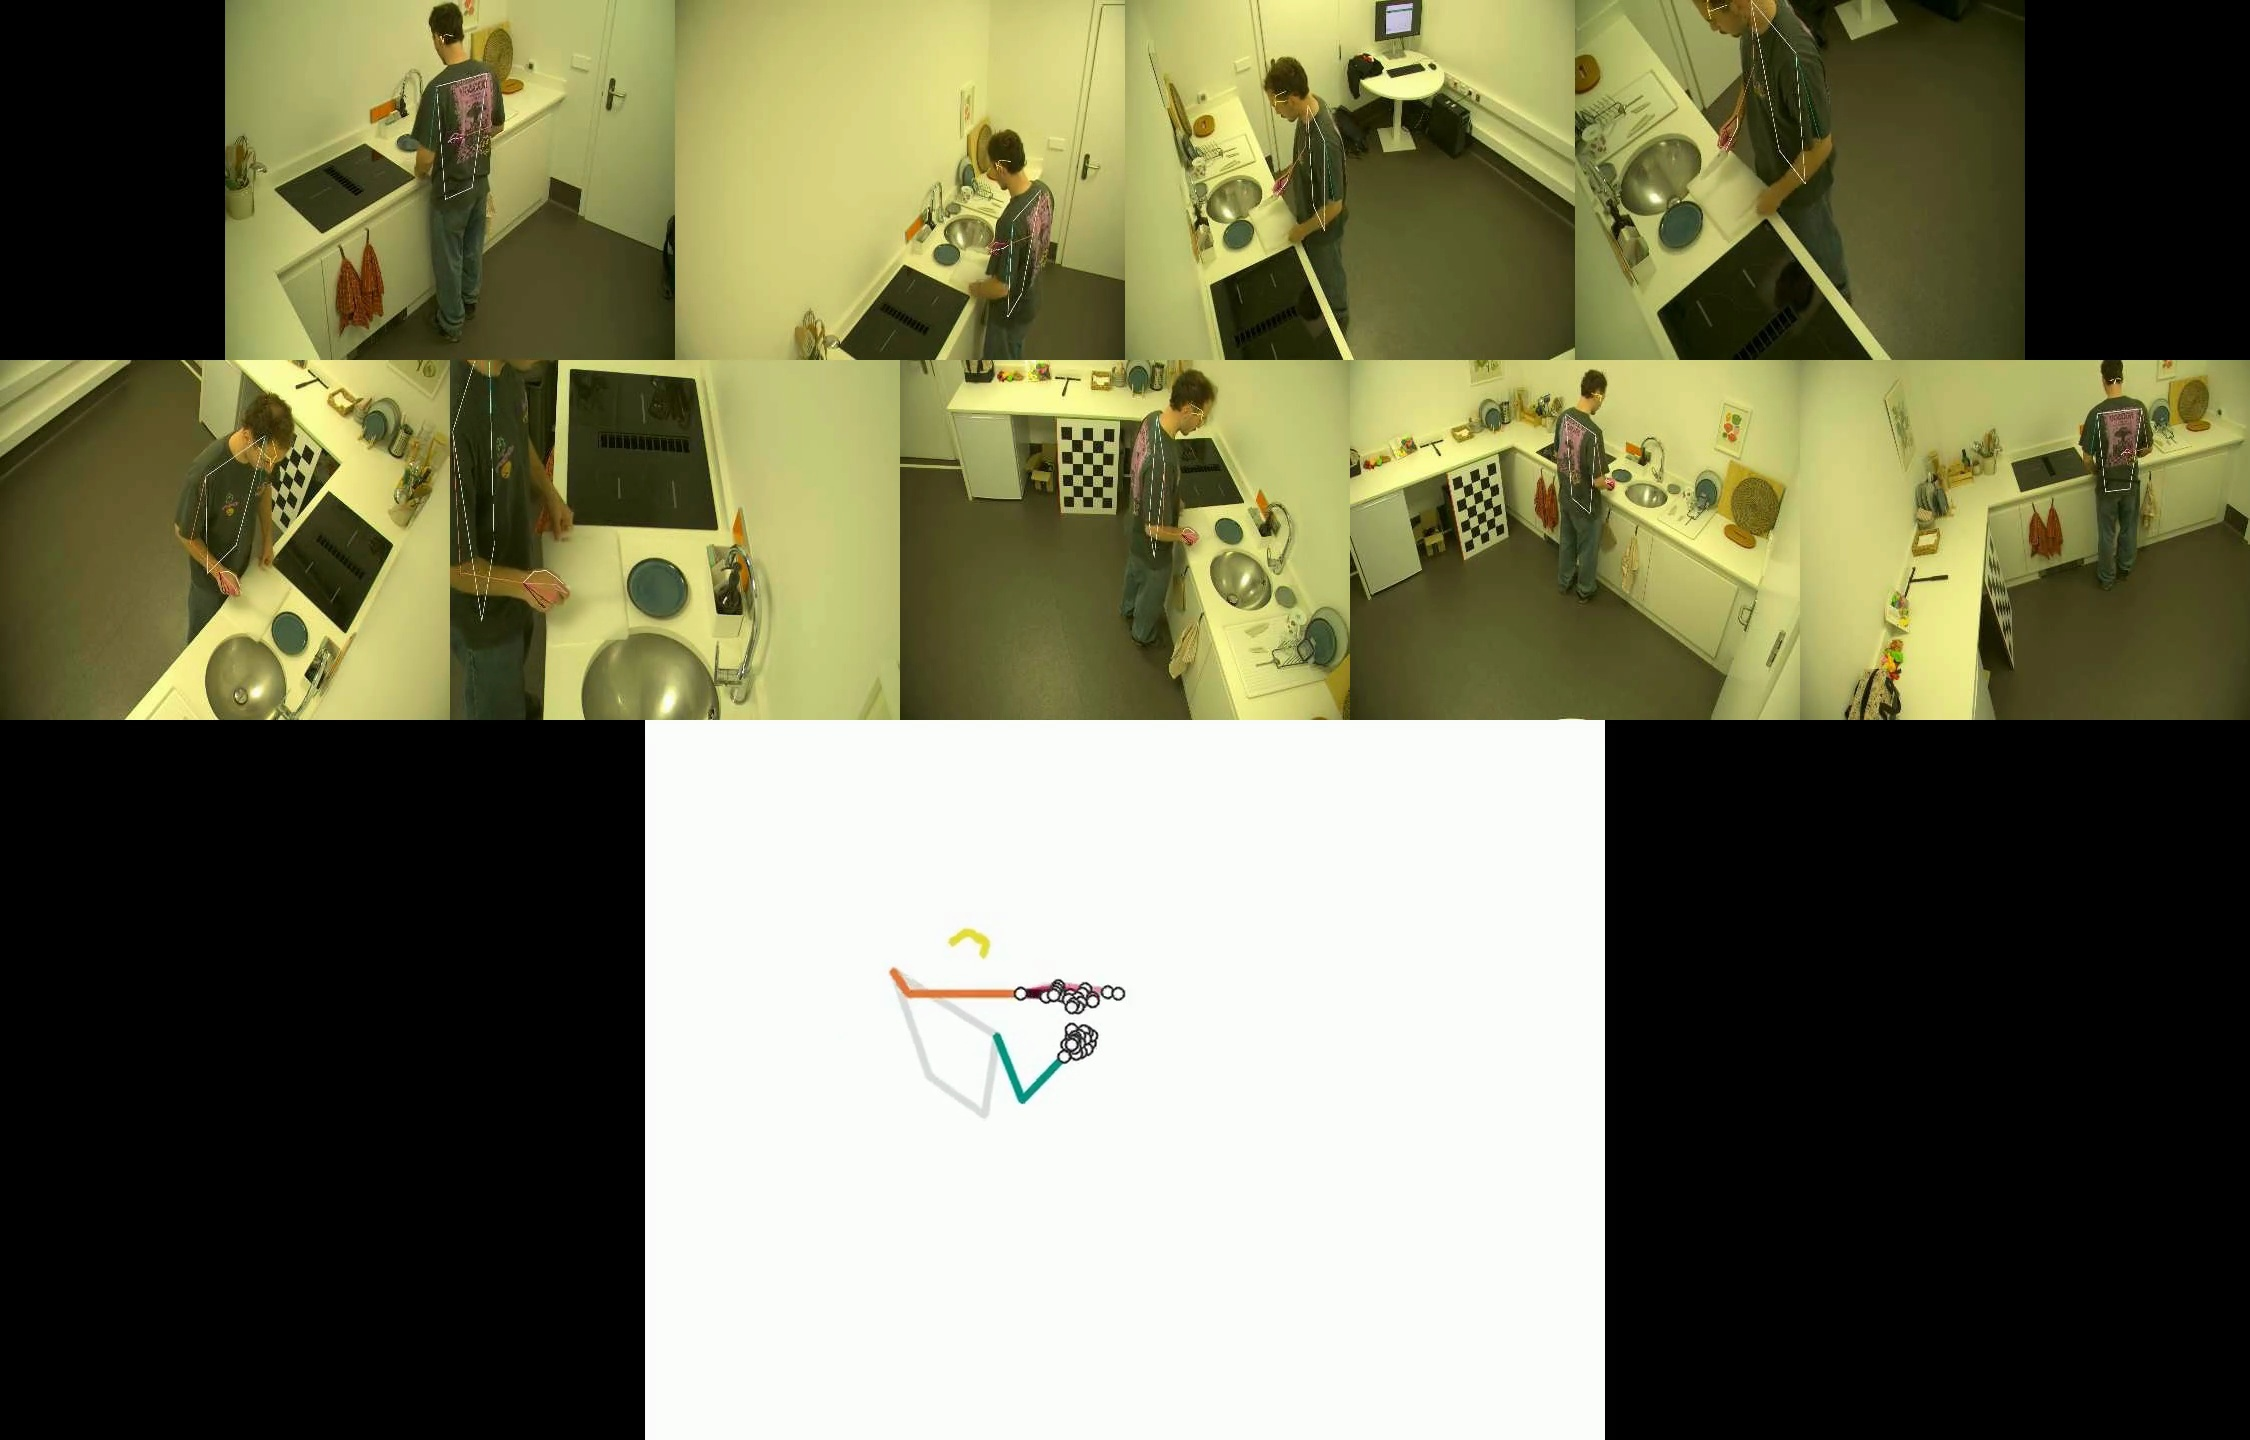

In [5]:
if RUN_MONTAGE:
    for video in ra.make_montage(PROJECT, RECORDINGS):
        print("montage:", video)

# Show one frame of each montage (open the .mp4 to watch it)
for rec in RECORDINGS:
    video = PROJECT / "videos_processed" / rec / "compilation.mp4"
    if video.exists():
        cap = cv2.VideoCapture(str(video))
        cap.set(cv2.CAP_PROP_POS_FRAMES, cap.get(cv2.CAP_PROP_FRAME_COUNT) // 3)
        ok, frame = cap.read()
        cap.release()
        if ok:
            display(Image(data=cv2.imencode(".jpg", frame)[1].tobytes(), width=900))

## Results

`<rec>_3Dlandmarks.npy` has shape `(frames, 75, 3)`: x, y, z in **mm**, origin at the corner of the floor checkerboard, z pointing up (so z is height above the floor). Points not seen by at least 2 cameras are NaN.

| indices | what |
|---|---|
| 0–32 | body ([MediaPipe pose](https://developers.google.com/mediapipe/solutions/vision/pose_landmarker) order: 0 nose, 11/12 shoulders, 15/16 wrists, 23/24 hips, 27/28 ankles, …; left/right = the person's) |
| 33–53 | right hand (33 = wrist), [MediaPipe hand](https://developers.google.com/mediapipe/solutions/vision/hand_landmarker) order |
| 54–74 | left hand (54 = wrist) |

In [6]:
REC = RECORDINGS[0]
data = ra.load_3d(PROJECT, REC)
fps = json.loads((PROJECT / "prep_manifest.json").read_text())["fps"]
t = np.arange(len(data)) / fps

# Trust a frame only if at least 4 cameras saw the body. With 2-3 cameras the
# triangulation can jump around: on the first capture every jump of the hips
# > 0.3 m between frames happened then (when the person walked out at the end).
n_cams = ra.cameras_seeing(PROJECT, REC)
reliable = n_cams >= 4
clean = data.copy()
clean[~reliable] = np.nan
print(f"{REC}: {len(data)} frames ({len(data) / fps:.0f} s); {(~reliable).sum()} frames "
      f"({(~reliable).mean():.0%}) seen by fewer than 4 cameras are NaN in `clean`")

seen = lambda idx: np.mean(~np.isnan(clean[:, idx, 0]))
print(f"   frames with 3D in `clean`: body {seen(ra.NOSE):.0%}, wrists {seen(16):.0%} right / {seen(15):.0%} left, "
      f"right hand {seen(ra.RIGHT_WRIST):.0%}, left hand {seen(ra.LEFT_WRIST):.0%}")
# Sanity check of the calibration's scale: standing nose height ~1.5-1.7 m, ankles ~0.1 m
print(f"   median height above floor: nose {np.nanmedian(clean[:, 0, 2]) / 1000:.2f} m, "
      f"ankles {np.nanmedian(clean[:, [27, 28], 2]) / 1000:.2f} m")

2026-10-20_103853_capture: 4118 frames (103 s); 286 frames (7%) seen by fewer than 4 cameras are NaN in `clean`
   frames with 3D in `clean`: body 93%, wrists 93% right / 93% left, right hand 51%, left hand 53%
   median height above floor: nose 1.53 m, ankles 0.06 m


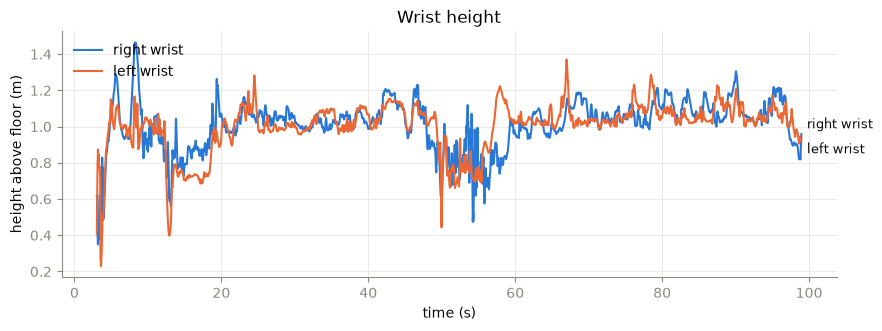

In [7]:
# Shared style: thin lines, recessive grid, fixed series colours (right = slot 1, left = slot 2)
RIGHT, LEFT, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})

# Wrist height over time (body-model wrists: 16 = right, 15 = left)
fig, ax = plt.subplots(figsize=(10, 3.2))
ends = []
for idx, colour, label in ((16, RIGHT, "right wrist"), (15, LEFT, "left wrist")):
    z = clean[:, idx, 2] / 1000
    ax.plot(t, z, color=colour, lw=1.5, label=label)
    valid = np.flatnonzero(~np.isnan(z))
    if len(valid):
        ends.append((z[valid[-1]], t[valid[-1]], label))
# Direct labels at the line ends, nudged apart so they never overlap
for k, (z_end, t_end, label) in enumerate(sorted(ends)):
    ax.annotate(label, (t_end, z_end), xytext=(4, -7 if k == 0 else 7), textcoords="offset points",
                color=INK, va="center", fontsize=9)
ax.set(xlabel="time (s)", ylabel="height above floor (m)", title="Wrist height")
ax.legend(frameon=False, loc="upper left")
plt.show()

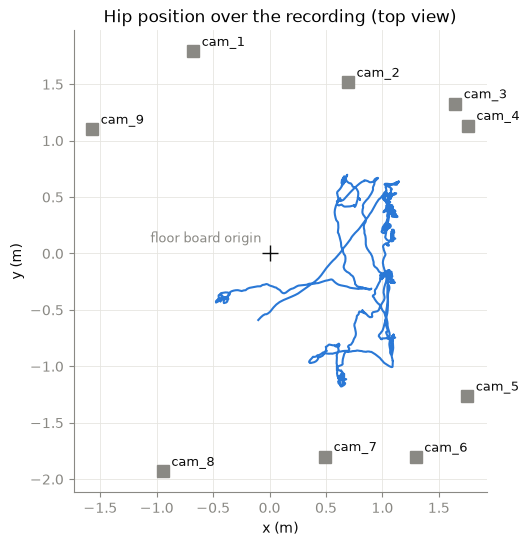

In [8]:
# Top view: where the person went (midpoint of the hips), with the cameras
cams = json.loads((PROJECT / "calibration_report.json").read_text())["cameras"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)  # frames without hips give NaN
    hips = np.nanmean(clean[:, [23, 24], :2], axis=1) / 1000

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(hips[:, 0], hips[:, 1], color=RIGHT, lw=1.5)
for c in cams:
    x, y = c["position_mm"][0] / 1000, c["position_mm"][1] / 1000
    ax.plot(x, y, "s", color=MUTED, ms=8)
    ax.annotate(c["camera_name"], (x, y), xytext=(6, 4), textcoords="offset points", color=INK, fontsize=9)
ax.plot(0, 0, "+", color=INK, ms=12)
ax.annotate("floor board origin", (0, 0), xytext=(-6, 8), textcoords="offset points", ha="right", color=MUTED, fontsize=9)
ax.set(xlabel="x (m)", ylabel="y (m)", title="Hip position over the recording (top view)")
ax.set_aspect("equal")
plt.show()

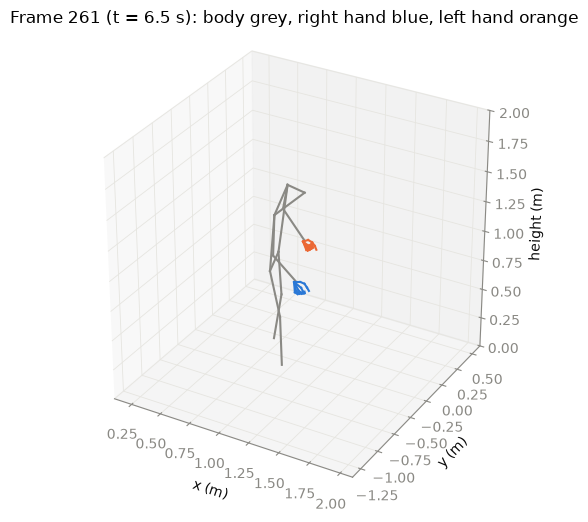

In [9]:
# One 3D frame: the frame with the most points seen
BODY_LINKS = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24), (23, 24),
              (23, 25), (25, 27), (24, 26), (26, 28), (0, 11), (0, 12)]
from athena.visualization import SKELETON_LINKS
HAND_LINKS = SKELETON_LINKS[16:]

frame = int(np.argmax(np.sum(~np.isnan(clean[:, :, 0]), axis=1)))
p = clean[frame] / 1000
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
for links, colour in ((BODY_LINKS, MUTED), (HAND_LINKS, None)):
    for a, b in links:
        if not np.isnan(p[[a, b]]).any():
            c = colour or (RIGHT if a < 54 else LEFT)
            ax.plot(*p[[a, b]].T, color=c, lw=1.5)
centre = np.nanmean(p, axis=0)
ax.set(xlim=(centre[0] - 1, centre[0] + 1), ylim=(centre[1] - 1, centre[1] + 1), zlim=(0, 2),
       xlabel="x (m)", ylabel="y (m)", zlabel="height (m)",
       title=f"Frame {frame} (t = {frame / fps:.1f} s): body grey, right hand blue, left hand orange")
ax.set_box_aspect((1, 1, 1))
plt.show()